# Encoding and Analyzing Training Clips
*Notes:*
- Taken from the processed MineRL training dataset

#### Imports

In [2]:
# Base notebook imports
import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch

# Model-related imports
from omegaconf import OmegaConf
from lewm.paths import repo_path
from lewm.models import ResNet

#### Create Embeddings

Episode length:  2122
Episode count:  210
(211, 192)


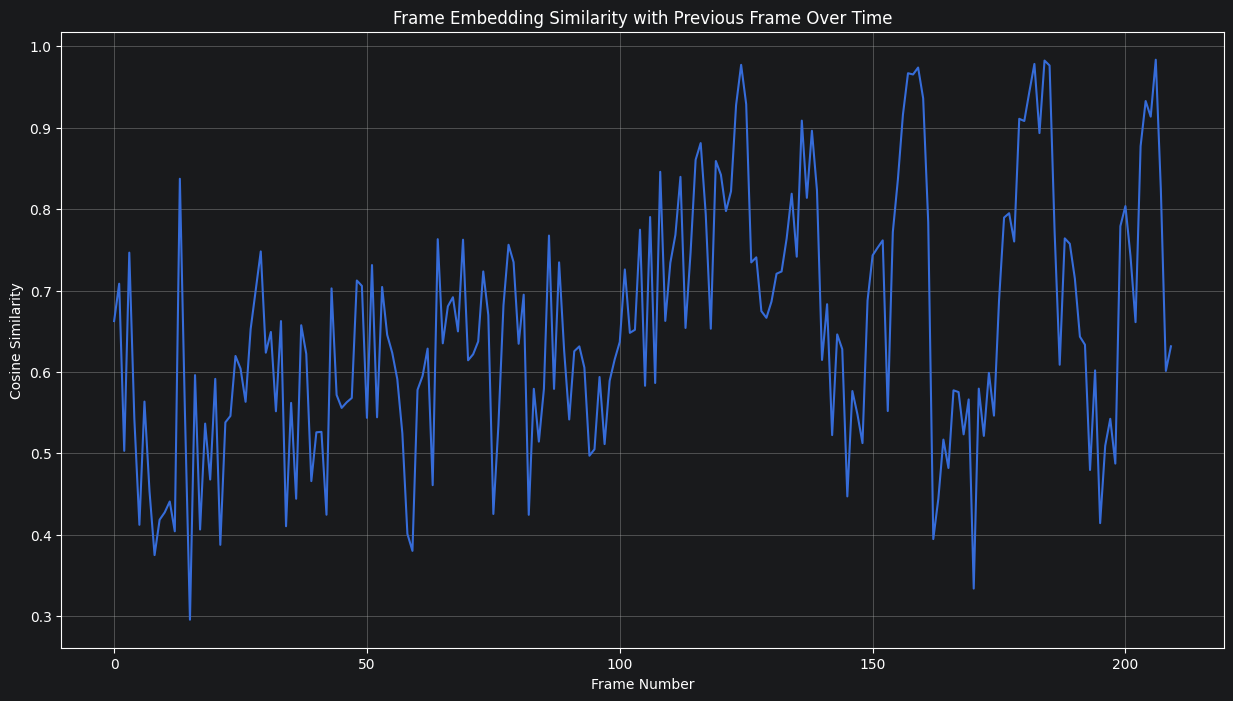

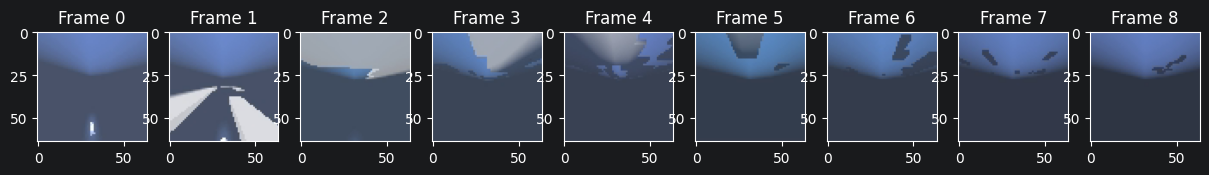

SANITY CHECK - Frames 0 and 209 cosine similarity: 0.3325437903404236


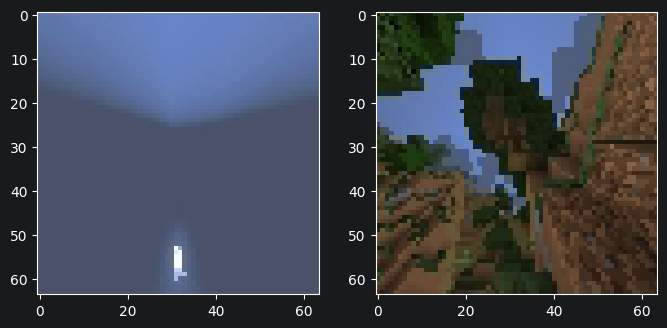

In [7]:
training_data_file = "../data/mineRL_training.h5"
smoke_prints = False

cfg = OmegaConf.load(repo_path("config", "lewm.yaml"))
encoder = ResNet(embedding_dim=cfg.vit.embedding_dim,)

with (h5py.File(training_data_file, "r") as file):
    # List data groups
    if smoke_prints:
        print(list(file.keys()))

    # Collect data groups
    actions = file["action"]
    ep_lengths = file["ep_len"]
    ep_offsets = file["ep_offset"]
    pixels = file["pixels"]

    # Print data groups
    if smoke_prints:
        print(actions)
        print(ep_lengths)
        print(ep_offsets)
        print(pixels)

    # ---------------------------------------------
    # Process an episode
    # ---------------------------------------------
    episode_length = file["ep_len"][0]
    print("Episode length: ", episode_length)
    print("Episode count: ", len(file["ep_offset"]))

    # Print an example frame
    if smoke_prints:
        # Convert frame to basic processed format for image printing
        frame = pixels[18]
        frame = np.transpose(frame, (1, 2, 0))
        plt.imshow(frame)

    # Collect embeddings for episode 0
    clip = pixels[:211]
    clip = torch.tensor(clip).float()
    with torch.no_grad():
        embeddings = encoder(clip).numpy()

    # Process and print embeddings
    embeddings.transpose()
    print(tuple(embeddings.shape))

    if smoke_prints:
        fig0 = plt.figure(figsize=(15, 12))
        plt.imshow(embeddings, aspect="auto")
        plt.colorbar()

    # ---------------------------------------------
    # Check cosine similarity
    # ---------------------------------------------
    similarities = []
    embeddings = torch.from_numpy(embeddings).float()
    lower_bound, upper_bound = 161, 164 # Minimum lower: 1 | Max suggested upper: episode_length
    for i, embed in enumerate(embeddings):
        if 0 < i <= upper_bound and i >= lower_bound:
            similarities.append(torch.nn.functional.cosine_similarity(embeddings[i-1], embed, dim=0).item())

    fig1 = plt.figure(figsize=(15, 8))
    plt.plot(similarities)
    plt.xlabel("Frame Number")
    plt.ylabel("Similarity")
    plt.ylabel("Cosine Similarity")
    plt.title("Frame Embedding Similarity with Previous Frame Over Time")
    plt.grid()
    plt.show()

    fig, axes = plt.subplots(nrows=1, ncols=min(upper_bound-lower_bound + 2, 9), figsize=(15, 8))
    for i in range(len(axes)):
        axes[i].imshow(np.transpose(pixels[lower_bound-1 + i], (1, 2, 0)))
        axes[i].set_title("Frame {}".format(lower_bound-1 + i))
    plt.show()

    # ---------------------------------------------
    # Sanity check
    # ---------------------------------------------
    print("SANITY CHECK - Frames 0 and 209 cosine similarity:",
          torch.nn.functional.cosine_similarity(embeddings[0], embeddings[209], dim=0).item())
    sanity_check_fig, sanity_check_axes = plt.subplots(nrows=1, ncols=2, figsize=(8, 16))
    sanity_check_axes[0].imshow(np.transpose(pixels[0], (1, 2, 0)))
    sanity_check_axes[1].imshow(np.transpose(pixels[209], (1, 2, 0)))
    plt.show()
